# Векторные представления текстов (ноутбук))

**Цель этого ноутбука:**
- Понять, как создавать и использовать векторные представления слов (Word Embeddings).
- Разобраться с предобученными моделями Word Embeddings (GloVe).
- Изучить, как текст преобразуется в числовой формат для нейронных сетей.
- Реализовать сверточную нейронную сеть (TextCNN) для классификации текстов.
- Научиться обрабатывать последовательности переменной длины с помощью padding.

**Проблемы, которые решаем:**
- "Материал более поверхностный" -> Детальные комментарии и объяснения.
- "Не хватает подробного материала про подбор гиперпараметров" -> Обсуждение гиперпараметров и переобучения.
- "Очень сложно вникнуть в логику работы элементов нейросети" -> Пошаговый разбор каждой части модели.
ти модели.


In [1]:
# !g1.1
%pip install gensim

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Импорт необходимых библиотек


In [2]:
# !g1.1
import torch # Основная библиотека для создания и обучения нейронных сетей
import torch.nn as nn # Модули нейронных сетей (слои, функции активации)
import numpy as np # Для работы с массивами и математическими операциями

# Импорт для работы с регулярными выражениями (для очистки текста)
import re
# Импорт для работы со строками (например, получения всех знаков пунктуации)
import string
# Counter - это удобный класс из модуля collections для подсчета хешируемых объектов.
# Идеально подходит для подсчета частоты слов в тексте.
from collections import Counter

## Загрузка предобученной модели GloVe (через gensim.downloader)
GloVe (Global Vectors for Word Representation) - это еще один метод для создания векторных представлений слов,
схожий по цели с Word2Vec, но использующий статистику глобальной со-встречаемости слов.
Почему GloVe-twitter-25?
- 'twitter': Эта модель была обучена на большом корпусе текстов из Twitter.
             Тексты из социальных сетей часто более неформальны и близки к отзывам,
             которые мы будем классифицировать (IMDB Dataset).
- '25': Обозначает размерность вектора для каждого слова (25 измерений).
        На лекции упоминалось, что FastText обычно использует 300 измерений.
        25 измерений - это меньший размер, что позволяет экономить память и ускорять вычисления,
        при этом сохраняя достаточно информации для демонстрации концепции.
        Для более сложных задач часто используют большую размерность (например, 100, 300).


In [3]:
# !g1.1
import gensim.downloader as api

# gensim.downloader позволяет легко загружать различные предобученные модели Word Embeddings.
# Это удобно, так как не нужно вручную скачивать и распаковывать файлы.

# Загружаем модель GloVe, обученную на твиттере, с размерностью векторов 25.
fasttext = api.load('glove-twitter-25')

# После загрузки 'fasttext' (на самом деле, это объект GloVe, но переменная так названа по аналогии с лекцией)
# содержит словарный запас и соответствующие им векторные представления.
# Теперь мы можем использовать его для получения векторов слов или поиска похожих слов.

## Быстрая проверка функциональности предобученной модели


In [4]:
# !g1.1
# Проверяем функциональность загруженной модели: поиск наиболее похожих слов.
# Метод most_similar() позволяет найти слова, чьи векторы находятся ближе всего
# в векторном пространстве к вектору заданного слова.
# 'positive' аргумент указывает слова, векторы которых добавляются.
# Вектор слова 'man'
print("Слова, наиболее похожие на 'man':")
print(fasttext.most_similar(positive=['man']))
# Ожидаем увидеть слова, связанные по смыслу или контексту, но поскольку это GloVe, обученный на Twitter,
# могут быть и менее очевидные связи, отражающие специфику этого корпуса (например, часто встречающиеся
# рядом служебные слова или сленг).

Слова, наиболее похожие на 'man':
[('was', 0.9065622091293335), ('i', 0.8880172371864319), ('he', 0.887438178062439), ('bad', 0.8846145272254944), ('even', 0.8832389712333679), ('be', 0.8784030079841614), ('we', 0.8764979243278503), ('not', 0.8764553666114807), ('had', 0.8762108683586121), ('glad', 0.8758711218833923)]


In [5]:
# !g1.1
# Демонстрация векторной арифметики, о которой говорилось на лекции: King - Man + Woman = Queen.
print("\nРезультат векторной арифметики (king - man + woman):")
print(fasttext.most_similar(positive=['king', 'woman'], negative=['man']))


Результат векторной арифметики (king - man + woman):
[('meets', 0.8841924071311951), ('prince', 0.832163393497467), ('queen', 0.8257461190223694), ('’s', 0.8174097537994385), ('crow', 0.813499391078949), ('hunter', 0.8131037950515747), ('father', 0.8115834593772888), ('soldier', 0.81113600730896), ('mercy', 0.8082392811775208), ('hero', 0.8082264065742493)]


## Подготовка данных: Vocabulary, чтение IMDB Dataset и отображение


In [6]:
# !g1.1
import pandas as pd # Для работы с табличными данными (DataFrame)
from torch.utils.data import Dataset # Базовый класс для создания кастомных датасетов в PyTorch

# Класс Vocabulary отвечает за создание словаря из текстового корпуса
# и преобразование слов в их числовые индексы (токены) и обратно.
class Vocabulary:
    def __init__(self, texts: list[str], min_freq: int = 10):
        # texts: Список строк (текстов), из которых будет построен словарь.
        # min_freq: Минимальная частота слова для включения его в словарь.
        #           Это позволяет отфильтровать редкие, возможно, ошибочные или неинформативные слова.
        #           Например, если min_freq=10, то слово должно встретиться не менее 10 раз,
        #           чтобы попасть в словарь.

        # 1. Объединяем все тексты в одну большую строку для удобства обработки.
        text = ' '.join(texts)

        # 2. Очистка текста:
        # Удаляем URL-адреса. Регулярное выражение ищет HTTP/HTTPS ссылки и заменяет их пробелами.
        text = re.sub(r"http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+", " ", text)
        # Оставляем только буквы (a-zA-Z), заменяя все остальные символы пробелами.
        # Это удаляет цифры, знаки пунктуации (кроме тех, что уже были заменены пробелами), специальные символы.
        # Для некоторых задач может потребоваться сохранение цифр или пунктуации.
        text = re.sub("[^a-zA-Z]", " ", text)
        # Заменяем все последовательности из двух и более пробелов на один пробел.
        # Это предотвращает создание пустых строк при разбиении на слова.
        while '  ' in text:
            text = text.replace('  ', ' ')

        # 3. Преобразование текста в список слов:
        # .strip(): Удаляет начальные и конечные пробелы.
        # .lower(): Приводит весь текст к нижнему регистру, чтобы 'Word' и 'word' считались одним и тем же.
        # .split(): Разбивает строку на список слов по пробелам.
        words = text.strip().lower().split()

        # 4. Подсчет частоты слов:
        # Counter(words) создает словарь, где ключи - это слова, а значения - их частота.
        c = Counter(words)

        # 5. Формирование словаря:
        # Создаем список уникальных слов, которые встречаются с частотой >= min_freq.
        self.vocabulary = list(set([word for word in words if c[word] >= min_freq]))
        # Добавляем специальный токен '<unk>' (Unknown - Неизвестное слово).
        # Этот токен будет использоваться для слов, которые не встретились в обучающем корпусе
        # или были отфильтрованы из-за низкой частоты.
        self.vocabulary.append('<unk>')

        # 6. Создание отображений слово <-> индекс:
        # _idx2word: Словарь, который по числовому индексу возвращает слово.
        self._idx2word = {i: word for i, word in enumerate(self.vocabulary)}
        # _word2idx: Словарь, который по слову возвращает его числовой индекс.
        self._word2idx = {word: i for i, word in enumerate(self.vocabulary)}

    # Метод для получения полного списка слов в словаре.
    def get_vocabulary(self):
        return self.vocabulary

    # Метод для получения слова по его индексу.
    def idx2word(self, idx: int):
        if idx not in self._idx2word:
            # Если индекс не найден (чего в идеале быть не должно, если индексы корректны),
            # возвращаем токен '<unk>'.
            return '<unk>'
        return self._idx2word[idx]

    # Метод для получения индекса слова.
    def word2idx(self, word: str):
        word = word.lower() # Приводим слово к нижнему регистру перед поиском.
        if word not in self._word2idx:
            # Если слово не найдено в словаре, возвращаем индекс токена '<unk>'.
            return self._word2idx['<unk>']
        return self._word2idx[word]

    # Метод для кодирования целого текста (предложения) в последовательность индексов.
    def encode(self, text):
        result = []
        # Разделяем текст на слова и для каждого слова получаем его индекс.
        for word in text.split():
            result.append(self.word2idx(word))
        return result

    # Метод для создания матрицы векторов слов на основе предобученной модели (например, GloVe).
    def build_vectors(self, fasttext_model): # Переименовал fasttext в fasttext_model для ясности
        vectors = []
        # Для каждого слова в нашем созданном словаре:
        for word in self.vocabulary:
            # Проверяем, есть ли это слово в предобученной модели.
            if fasttext_model.has_index_for(word):
                # Если есть, добавляем его вектор.
                vectors.append(fasttext_model[word])
            else:
                # Если слова нет в предобученной модели (например, наш '<unk>' токен, или очень редкое слово),
                # добавляем нулевой вектор. Эти векторы могут быть обучены с нуля в процессе тренировки модели.
                vectors.append(np.zeros(fasttext_model.vector_size)) # Используем .vector_size для гибкости
        return np.stack(vectors) # Объединяем список векторов в один NumPy массив.

# Загружаем датасет IMDB для анализа тональности.
# Этот датасет содержит 50 000 отзывов к фильмам, каждый помечен как "positive" или "negative".
df = pd.read_csv('IMDB Dataset.csv')

# Выводим первые несколько строк датафрейма, чтобы ознакомиться с данными.
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


## Создание кастомного Dataset для PyTorch (IMDB)


In [7]:
# !g1.1
# Класс IMDB наследуется от torch.utils.data.Dataset,
# что позволяет использовать его с PyTorch DataLoader для эффективной загрузки данных в батчах.
class IMDB(Dataset):
    def __init__(self, path):
        # path: Путь к файлу CSV с датасетом IMDB.
        self.df = pd.read_csv(path) # Загружаем DataFrame.

        # Извлекаем все тексты отзывов.
        texts = self.df['review'].values

        # Инициализируем наш Vocabulary класс.
        # min_freq=5: Слова, встречающиеся реже 5 раз, будут заменены на <unk>.
        # Это более мягкий порог, чем 10, упомянутый в лекции, и подходит для данного размера датасета.
        self.vocab = Vocabulary(texts, min_freq=5)

        # Создаем отображение для целевых переменных (сентимента) из строковых меток в числовые.
        # 'positive' -> 0, 'negative' -> 1.
        self.label2idx = {'positive': 0, 'negative': 1}

    # Метод __getitem__ вызывается DataLoader'ом для получения одного объекта из датасета по индексу.
    def __getitem__(self, idx):
        # Получаем текст отзыва по индексу.
        text = self.df['review'].loc[idx]
        # Получаем метку тональности и преобразуем ее в числовой индекс.
        label = self.label2idx[self.df['sentiment'].loc[idx]]

        # Кодируем текст в последовательность числовых индексов с помощью нашего словаря.
        # torch.LongTensor: Используется для индексов или целых чисел, требующих дискретного представления.
        text_encoded = torch.LongTensor(self.vocab.encode(text))
        # Преобразуем метку в FloatTensor.
        # [label]: Оборачиваем метку в список, чтобы создать тензор с одним элементом,
        # что удобно для функции потерь nn.BCEWithLogitsLoss.
        label_tensor = torch.FloatTensor([label])

        return text_encoded, label_tensor

    # Метод __len__ возвращает общее количество объектов в датасете.
    def __len__(self):
        return len(self.df)

# Создаем экземпляр нашего датасета IMDB.
dataset = IMDB('IMDB Dataset.csv')

# Посмотрим на первый элемент датасета, чтобы убедиться, что он правильно кодируется.
text_example, label_example = dataset[0]
print("Пример закодированного текста (первые 100 токенов):", text_example[:100])
print("Пример метки:", label_example)
print("Размер словаря (включая <unk>):", len(dataset.vocab.vocabulary))


Пример закодированного текста (первые 100 токенов): tensor([38655, 12974,  5319,  3842, 35699, 31414, 29811, 25059, 32782, 11179,
         1135, 39272, 36326, 32223, 39272,   644, 39272, 20408,  6706, 39272,
        22516, 20403, 32529,  4097, 12525, 19814, 21134, 39272, 39272, 39272,
        19941, 34943, 25059, 32053, 38877,  8778, 36326,  9004, 12852, 35526,
        35370, 19523, 15791, 12974, 39272,  8396, 21836, 22657, 35211,  1390,
         5319, 26128, 39272, 27273, 39272, 20403, 32529, 14569, 27490, 38713,
         1262,  5319,  9225, 16371,  9970, 39272, 20403, 38713,  1329,  7593,
         7837, 21134, 11207, 11003, 39272,  8028,  9970, 39272, 12852, 32529,
        39272, 22657,  5319,  8900, 21829, 12974,  5319, 39272, 39272, 39272,
        32529,  2237, 36326, 22516, 25059, 32529,  5319, 28093, 33163, 11003])
Пример метки: tensor([0.])
Размер словаря (включая <unk>): 39273


## Разбиение на train/test


In [8]:
# !g1.1
from torch.utils.data import random_split

# Разделяем датасет на обучающую и тестовую выборки.
# int(len(dataset) * 0.9): 90% данных идут в обучающую выборку.
# len(dataset) - int(len(dataset) * 0.9): Оставшиеся 10% идут в тестовую выборку.
train_dataset, test_dataset = random_split(
    dataset,
    (int(len(dataset) * 0.9), len(dataset) - int(len(dataset) * 0.9))
)

print(f"Размер обучающей выборки: {len(train_dataset)}")
print(f"Размер тестовой выборки: {len(test_dataset)}")


Размер обучающей выборки: 45000
Размер тестовой выборки: 5000


## Padding и collate_fn для DataLoader


In [9]:
# !g1.1
from torch.nn.utils.rnn import pad_sequence

# Обработка последовательностей переменной длины (Padding):
# На лекции обсуждалось, что тексты имеют переменную длину. Нейронные сети,
# особенно те, которые работают с батчами, ожидают, что все входные данные в батче
# будут иметь одинаковую размерность.
# Padding (дополнение) - это техника, при которой более короткие последовательности
# дополняются специальным "паддинг"-токеном до максимальной длины в текущем батче (или до фиксированной длины).

# pad_idx: Индекс токена, используемого для заполнения.
# Мы выбираем индекс, который находится за пределами всех существующих индексов слов в словаре.
# len(dataset.vocab.vocabulary) - это число, которое равно размеру словаря,
# включая токен '<unk>', и оно будет на 1 больше максимального индекса слова.
# Таким образом, этот индекс не будет конфликтовать ни с одним реальным словом.
pad_idx = len(dataset.vocab.vocabulary)
print(f"Индекс для padding: {pad_idx}")

# collate_fn - это функция, которая используется DataLoader'ом для обработки списка
# отдельных элементов в батч. Мы используем ее для применения padding.
def collate_fn(batch):
    # batch: Список кортежей, где каждый кортеж содержит (текст_тензор, метка_тензор).
    # [b[0] for b in batch]: Извлекаем все тензоры текстов из батча.
    # pad_sequence: Функция PyTorch, которая дополняет последовательности до максимальной длины в списке.
    #   - padding_value=pad_idx: Указывает, каким значением заполнять.
    #   - batch_first=True: Делает так, что размерность батча будет первой (Batch_Size, Sequence_Length).
    texts = pad_sequence([b[0] for b in batch], padding_value=pad_idx, batch_first=True)

    # [b[1] for b in batch]: Извлекаем все тензоры меток из батча.
    # torch.stack: Объединяет список тензоров вдоль новой размерности.
    # В результате получаем один тензор меток размером (Batch_Size, 1).
    labels = torch.stack([b[1] for b in batch])

    return texts, labels

Индекс для padding: 39273


## DataLoader'ы и просмотр батча


In [10]:
# !g1.1
from torch.utils.data import DataLoader

# Создаем DataLoader'ы для обучающей и тестовой выборок.
# DataLoader - это итератор, который предоставляет батчи данных.
#   - dataset: Объект нашего кастомного датасета.
#   - batch_size: Количество объектов в каждом батче.
#   - collate_fn: Наша пользовательская функция для обработки батчей (применения padding).
#   - pin_memory=True: Позволяет DataLoader'у быстрее переносить данные на GPU.
#   - num_workers: Количество подпроцессов для загрузки данных. Для простых задач можно 0.
train_loader = DataLoader(train_dataset, batch_size=64, collate_fn=collate_fn, pin_memory=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=64, collate_fn=collate_fn, pin_memory=True, num_workers=0)

# Получаем один батч из train_loader, чтобы посмотреть, как выглядят данные после padding.
b = next(iter(train_loader))

# Выводим батч.
# b[0] - это тензор с текстами (Batch_Size, Max_Sequence_Length).
# b[1] - это тензор с метками (Batch_Size, 1).
print("Пример батча (texts, labels):")
print(b)


Пример батча (texts, labels):
[tensor([[31318, 29998, 21764,  ..., 39273, 39273, 39273],
        [ 5017, 39272, 39272,  ..., 39273, 39273, 39273],
        [  388, 22657, 39272,  ..., 39273, 39273, 39273],
        ...,
        [38021,  9004,   878,  ..., 39273, 39273, 39273],
        [38021,  7011, 14712,  ..., 39273, 39273, 39273],
        [35867, 38021, 21724,  ..., 39273, 39273, 39273]]), tensor([[1.],
        [1.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [1.],
        [0.],
        [0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
    

In [11]:
# !g1.1
# Посмотрим на тензор текстов из батча более детально.
print("Тензор текстов в батче (b[0]):")
print(b[0])
print(f"Размерность тензора текстов: {b[0].shape}")
# Можно увидеть, что конец каждой последовательности (строки) заполнен pad_idx,
# если оригинальный текст был короче максимальной длины в этом батче.


Тензор текстов в батче (b[0]):
tensor([[31318, 29998, 21764,  ..., 39273, 39273, 39273],
        [ 5017, 39272, 39272,  ..., 39273, 39273, 39273],
        [  388, 22657, 39272,  ..., 39273, 39273, 39273],
        ...,
        [38021,  9004,   878,  ..., 39273, 39273, 39273],
        [38021,  7011, 14712,  ..., 39273, 39273, 39273],
        [35867, 38021, 21724,  ..., 39273, 39273, 39273]])
Размерность тензора текстов: torch.Size([64, 773])


## Архитектура: TextCNN


In [12]:
# !g1.1
# https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html
import torch.nn.functional as F # Функциональный API PyTorch (ReLU, Max Pooling и т.д.)

# TextCNN (Convolutional Neural Network for Text)
# Эта архитектура использует свертки для извлечения признаков из текста.
# Основная идея: рассматривать последовательность векторов слов как "изображение"
# и применять к ней сверточные фильтры для обнаружения локальных паттернов (n-грамм, фраз).
class TextCNN(nn.Module):
    def __init__(self, vocab_size: int, embedding_dim: int, pad_idx: int):
        # vocab_size: Общее количество уникальных токенов в словаре (включая <unk> и padding_idx).
        # embedding_dim: Размерность вектора каждого слова (например, 25 для GloVe-twitter-25).
        # pad_idx: Индекс токена, используемого для padding.

        super().__init__() # Вызов конструктора родительского класса nn.Module.

        # 1. Слой Embedding:
        # nn.Embedding - это слой, который хранит векторные представления для каждого слова в словаре.
        # Он действует как "lookup table": по индексу слова он возвращает соответствующий ему вектор.
        #   - vocab_size: Размер словаря. Указываем 'количество слов в словаре + 1'
        #                 (плюс один для pad_idx, который является отдельным токеном).
        #   - embedding_dim: Размерность каждого вектора слова.
        #   - padding_idx = pad_idx: Важный параметр! Он указывает, что вектор для этого индекса
        #                            не должен обновляться во время обучения (его градиент будет равен нулю)
        #                            и часто инициализируется нулями. Это предотвращает влияние паддинга на обучение.
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx = pad_idx)

        # 2. Сверточные слои (Convolutional Layers):
        # nn.ModuleList используется для хранения списка модулей (слоев).
        # Мы создаем несколько параллельных сверточных слоев с разными размерами ядер (filter_sizes).
        # Это позволяет модели улавливать n-граммы разной длины (например, биграммы, триграммы и т.д.).
        self.convs = nn.ModuleList(
            [
                nn.Conv2d(
                    in_channels = 1, # Входной канал. Текст рассматривается как одноканальное "изображение".
                                     # Представьте, что у вас есть матрица (sequence_length, embedding_dim).
                                     # Мы добавим ей размерность канала (batch_size, 1, sequence_length, embedding_dim).
                    out_channels = 16, # Количество выходных карт признаков (фильтров).
                                        # Каждый фильтр будет искать определенный паттерн.
                    kernel_size = (fs, embedding_dim) # Размер ядра свертки.
                                                    # fs (filter_size): Высота ядра. Это количество слов в n-грамме,
                                                    #                   которую свертка будет анализировать (2, 3, 4 или 5 слов).
                                                    # embedding_dim: Ширина ядра. Ядро охватывает весь вектор слова.
                                                    #                Это гарантирует, что свертка движется только по оси времени (по словам).
                )
                for fs in [2, 3, 4, 5] # Размеры фильтров: 2-граммы, 3-граммы, 4-граммы, 5-граммы.
            ]
        )

        # 3. Полносвязный слой (Fully Connected Layer):
        # Принимает на вход конкатенированные выходы всех сверточных слоев после пулинга.
        #   - 4 * 16: У нас 4 сверточных слоя, каждый из которых выдает 16 выходных каналов.
        #             После пулинга каждый канал дает одно число, поэтому 4 * 16 = 64 признака.
        #   - 1: Выходной размер 1, так как мы решаем задачу бинарной классификации (позитивный/негативный отзыв).
        #        Этот выход будет логитом, который затем передается в сигмоиду.
        self.fc = nn.Linear(len([2,3,4,5]) * 16, 1) # Используем len() для гибкости

        # 4. Dropout:
        # nn.Dropout - слой регуляризации, который случайно "выключает" часть нейронов во время обучения.
        # Это помогает предотвратить переобучение, заставляя модель не слишком сильно полагаться
        # на какие-то конкретные признаки. 0.2 - вероятность "выключить" нейрон.
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        # x: Входной тензор индексов слов (Batch_Size, Sequence_Length).

        # 1. Пропускаем входные индексы через слой Embedding.
        # Результат: тензор векторов слов (Batch_Size, Sequence_Length, Embedding_Dim).
        x = self.embedding(x)

        # 2. Добавляем размерность канала для сверточных слоев.
        # Результат: (Batch_Size, 1, Sequence_Length, Embedding_Dim).
        # Это необходимо, так как Conv2d ожидает 4D вход.
        x = x.unsqueeze(1)

        # 3. Применяем каждый сверточный слой параллельно:
        #   - conv(x): Применяем свертку. Выход: (Batch_Size, Out_Channels, New_Seq_Len, 1).
        #   - F.relu(...): Применяем функцию активации ReLU (Rectified Linear Unit),
        #                  которая вводит нелинейность в модель.
        #   - .squeeze(3): Удаляем последнюю размерность (которая равна 1 после свертки по всей ширине Embedding_Dim).
        #                  Выход после squeeze(3): (Batch_Size, Out_Channels, New_Seq_Len).
        x = [F.relu(conv(x)).squeeze(3) for conv in self.convs]

        # 4. Применяем Max Pooling по всей длине последовательности для каждого сверточного выхода:
        #   - F.max_pool1d: Применяем 1D Max Pooling.
        #                   Pooling_size = _.shape[2]: Делаем pooling по всей оставшейся длине последовательности.
        #                   Это означает, что для каждого фильтра мы берем максимальное значение,
        #                   обнаруженное в любом месте текста. Это помогает уловить "самый сильный" паттерн.
        #   - .squeeze(2): Удаляем размерность длины последовательности (которая становится 1 после max pooling).
        #                  Выход после squeeze(2): (Batch_Size, Out_Channels).
        x = [F.max_pool1d(_, _.shape[2]).squeeze(2) for _ in x]

        # 5. Конкатенируем выходы всех сверточных слоев:
        # torch.cat(x, dim = 1): Объединяем полученные тензоры по второй размерности (по каналам).
        # Результат: (Batch_Size, Total_Out_Channels), где Total_Out_Channels = 4 * 16 = 64.
        # Затем применяем Dropout для регуляризации.
        x = self.dropout(torch.cat(x, dim = 1))

        # 6. Пропускаем через финальный полносвязный слой.
        # Результат: логит для каждого объекта в батче (Batch_Size, 1).
        return self.fc(x)

# Инициализируем модель TextCNN.
# vocab_size: Размер словаря + 1 (для pad_idx).
# embedding_dim: Размерность векторов слов (25).
# pad_idx: Индекс токена padding.
model = TextCNN(vocab_size=len(dataset.vocab.vocabulary) + 1, embedding_dim=25, pad_idx=pad_idx)

print("Модель TextCNN успешно создана.")
print(model)


Модель TextCNN успешно создана.
TextCNN(
  (embedding): Embedding(39274, 25, padding_idx=39273)
  (convs): ModuleList(
    (0): Conv2d(1, 16, kernel_size=(2, 25), stride=(1, 1))
    (1): Conv2d(1, 16, kernel_size=(3, 25), stride=(1, 1))
    (2): Conv2d(1, 16, kernel_size=(4, 25), stride=(1, 1))
    (3): Conv2d(1, 16, kernel_size=(5, 25), stride=(1, 1))
  )
  (fc): Linear(in_features=64, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)


## Подготовка и загрузка предобученных эмбеддингов в слой Embedding


In [13]:
# !g1.1
# Строим матрицу векторов слов на основе нашего словаря и предобученной модели GloVe.
# Эта матрица будет содержать векторы для всех слов из нашего словаря.
# Для слов, которых нет в GloVe, будут использованы нулевые векторы (как определено в Vocabulary.build_vectors).
vectors = dataset.vocab.build_vectors(fasttext)

# Проверяем размерность полученной матрицы векторов.
# Ожидаем: (количество_слов_в_словаре + 1_для_unk, embedding_dim).
# +1 здесь не для pad_idx, а для <unk> в нашем Vocabulary.
print(f"Размерность матрицы векторов (vectors.shape): {vectors.shape}")


Размерность матрицы векторов (vectors.shape): (39273, 25)


In [14]:
# !g1.1
# Проверяем размерность матрицы весов слоя Embedding в нашей модели.
# Она должна быть (vocab_size, embedding_dim).
# vocab_size = len(dataset.vocab.vocabulary) + 1 (для pad_idx).
# embedding_dim = 25.
print(f"Размерность матрицы весов Embedding слоя модели (model.embedding.weight.shape): {model.embedding.weight.shape}")

# Загружаем предобученные векторы в слой Embedding нашей модели.
# model.embedding.weight.data: Это непосредственно тензор весов слоя Embedding.
# [:] = torch.from_numpy(vectors): Мы присваиваем ему значения из нашей матрицы 'vectors'.
#     - [:len(vectors)]: Мы загружаем векторы только для тех слов, для которых они были
#                       сгенерированы в `build_vectors`. Это включает все слова из словаря и <unk>.
#                       Последний элемент в `model.embedding.weight` соответствует `pad_idx`,
#                       и он останется без изменений (нулевым, если `padding_idx` был правильно указан
#                       при инициализации `nn.Embedding` и PyTorch его обнуляет по умолчанию).
model.embedding.weight.data[:len(vectors)] = torch.from_numpy(vectors)

# Обратите внимание: по умолчанию эти веса будут обновляться в процессе обучения.
# Если бы мы хотели "заморозить" их (использовать только предобученные, без дообучения),
# мы бы написали: model.embedding.weight.requires_grad = False.
# В данном случае мы позволяем модели дообучать эти векторы, что часто дает лучшие результаты.
print("\nПредобученные векторы загружены в слой Embedding.")


Размерность матрицы весов Embedding слоя модели (model.embedding.weight.shape): torch.Size([39274, 25])

Предобученные векторы загружены в слой Embedding.


In [15]:
# !g1.1
# Выводим веса слоя Embedding после загрузки предобученных векторов.
# Можно заметить, что первые строки соответствуют загруженным векторам.
# Последняя строка (соответствующая pad_idx) будет состоять из нулей,
# потому что мы указали `padding_idx` при инициализации `nn.Embedding`.
# Предпоследняя строка (соответствующая '<unk>') также будет нулевой,
# если слово '<unk>' не имело вектора в `fasttext` и было инициализировано нулями в `build_vectors`.
print("Веса Embedding слоя после загрузки предобученных векторов:")
print(model.embedding.weight)

# Снова проверяем размерность, чтобы убедиться, что она не изменилась.
print(f"\nРазмерность матрицы весов Embedding слоя модели (model.embedding.weight.shape): {model.embedding.weight.shape}")


Веса Embedding слоя после загрузки предобученных векторов:
Parameter containing:
tensor([[-1.4367,  0.5755,  1.2215,  ..., -0.3592,  0.0807, -0.4431],
        [ 0.0715,  0.2842,  0.4475,  ...,  0.7300, -0.7914,  0.3493],
        [-1.4727,  0.9431,  0.2407,  ...,  0.2703, -0.7038, -1.0548],
        ...,
        [ 0.0487,  0.8954,  0.5516,  ..., -0.0188, -0.1540, -1.1717],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],
       requires_grad=True)

Размерность матрицы весов Embedding слоя модели (model.embedding.weight.shape): torch.Size([39274, 25])


## Функции обучения и валидации


In [16]:
# !g1.1
from tqdm import tqdm # Для отображения прогресс-баров в циклах обучения


# Функция для расчета бинарной точности (Binary Accuracy).
# Используется для оценки производительности модели в задачах бинарной классификации.
def binary_accuracy(preds, y):
    # preds: Логиты (сырые выходы модели) перед функцией активации (например, сигмоида).
    # y: Истинные метки (0 или 1).

    # 1. Применяем сигмоиду к логитам. Сигмоида преобразует любое вещественное число в диапазон (0, 1),
    #    что можно интерпретировать как вероятность принадлежности к положительному классу.
    probabilities = torch.sigmoid(preds)
    # 2. Округляем вероятности до ближайшего целого (0 или 1).
    #    Если вероятность >= 0.5, округляется до 1 (положительный класс).
    #    Если вероятность < 0.5, округляется до 0 (отрицательный класс).
    rounded_preds = torch.round(probabilities)
    # 3. Сравниваем округленные предсказания с истинными метками.
    #    (rounded_preds == y) создает булевый тензор (True/False).
    #    .float() преобразует True в 1.0, False в 0.0.
    correct = (rounded_preds == y).float()
    # 4. Вычисляем точность: сумма всех правильных предсказаний, деленная на общее количество объектов.
    acc = correct.sum() / len(correct)
    return acc


# Функция для выполнения одного цикла обучения (эпохи).
def train(model) -> float:
    # model.train() переводит модель в режим обучения.
    # Это важно для слоев вроде Dropout и BatchNorm, которые ведут себя по-разному в обучении и оценке.
    model.train()

    train_loss = 0 # Суммарная ошибка за эпоху
    train_accuracy = 0 # Суммарная точность за эпоху

    # Итерируемся по батчам данных из обучающего DataLoader'а.
    # tqdm используется для красивого прогресс-бара.
    for x, y in tqdm(train_loader, desc='Train'):
        # 1. Перемещаем данные на используемое устройство (GPU/CPU).
        x, y = x.to(device), y.to(device)

        # 2. Обнуляем градиенты оптимизатора.
        # Это необходимо, потому что PyTorch накапливает градиенты по умолчанию.
        optimizer.zero_grad()

        # 3. Пропускаем входные данные через модель (прямой проход).
        # output: логиты предсказаний модели.
        output = model(x)

        # 4. Вычисляем функцию потерь (ошибку) между предсказаниями и истинными метками.
        loss = loss_fn(output, y)

        # 5. Накапливаем значения ошибки и точности для логирования.
        train_loss += loss.item() # .item() извлекает скалярное значение из тензора.
        train_accuracy += binary_accuracy(output, y)

        # 6. Обратное распространение ошибки (Backpropagation).
        # loss.backward() вычисляет градиенты всех параметров модели относительно ошибки.
        loss.backward()

        # 7. Шаг оптимизации.
        # optimizer.step() обновляет веса модели, используя вычисленные градиенты.
        optimizer.step()

    # 8. Усредняем ошибку и точность по всем батчам за эпоху.
    train_loss /= len(train_loader)
    train_accuracy /= len(train_loader)

    return train_loss, train_accuracy


In [17]:
# !g1.1
import torch


# @torch.inference_mode() - декоратор для отключения отслеживания градиентов.
# Это оптимизация для фазы оценки, так как градиенты не нужны, и это экономит память/вычисления.
@torch.inference_mode()
# Функция для оценки качества модели на валидационной/тестовой выборке.
def evaluate(model, loader) -> tuple[float, float]:
    # model.eval() переводит модель в режим оценки.
    # Это отключает Dropout и заставляет BatchNorm использовать зафиксированные статистики.
    model.eval()

    total_loss = 0 # Суммарная ошибка
    total_accuracy = 0 # Суммарная точность

    # Итерируемся по батчам данных из DataLoader'а для оценки.
    for x, y in tqdm(loader, desc='Evaluation'):
        # 1. Перемещаем данные на используемое устройство.
        x, y = x.to(device), y.to(device)

        # 2. Прямой проход модели.
        output = model(x)

        # 3. Вычисляем функцию потерь.
        loss = loss_fn(output, y)

        # 4. Накапливаем ошибку и точность.
        total_loss += loss.item()
        total_accuracy += binary_accuracy(output, y)

    # 5. Усредняем ошибку и точность.
    total_loss /= len(loader)
    total_accuracy /= len(loader)

    return total_loss, total_accuracy


## Визуализация метрик


In [18]:
# !g1.1
import matplotlib.pyplot as plt # Для построения графиков
from IPython.display import clear_output # Для очистки вывода в Jupyter Notebook


# Функция для построения графиков ошибок и точности.
def plot_stats(train_loss, valid_loss, train_accuracy, valid_accuracy, title):

    # Переводим все тензоры в CPU + numpy (если это torch.Tensor)
    def to_numpy(x):
        if isinstance(x, torch.Tensor):
            return x.detach().cpu().numpy()
        return np.array(x)

    train_loss = [to_numpy(v) for v in train_loss]
    valid_loss = [to_numpy(v) for v in valid_loss]
    train_accuracy = [to_numpy(v) for v in train_accuracy]
    valid_accuracy = [to_numpy(v) for v in valid_accuracy]

    plt.figure(figsize=(16, 8))
    plt.title(title + ' accuracy')
    plt.plot(train_accuracy, label='Train accuracy')
    plt.plot(valid_accuracy, label='Valid accuracy')
    plt.legend()
    plt.show()

    plt.figure(figsize=(16, 8))
    plt.title(title + ' loss')
    plt.plot(train_loss, label='Train loss')
    plt.plot(valid_loss, label='Valid loss')
    plt.legend()
    plt.show()



## Цикл обучения + валидация по эпохам


In [19]:
# !g1.1
# Функция для запуска полного цикла обучения и валидации на несколько эпох.
def whole_train_valid_cycle(model, num_epochs, title):
    train_loss_history, valid_loss_history = [], [] # Списки для хранения истории ошибок
    train_accuracy_history, valid_accuracy_history = [], [] # Списки для хранения истории точности

    # Цикл по каждой эпохе
    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}") # Выводим текущую эпоху
        # Запускаем обучение на одной эпохе
        train_loss, train_accuracy = train(model)
        # Оцениваем модель на тестовой выборке
        valid_loss, valid_accuracy = evaluate(model, test_loader)

        # Добавляем результаты в истории
        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)
        train_accuracy_history.append(train_accuracy)
        valid_accuracy_history.append(valid_accuracy)

        clear_output(wait=True) # Очищаем вывод, чтобы графики обновлялись на месте

        # Строим графики ошибок и точности
        plot_stats(
            train_loss_history, valid_loss_history,
            train_accuracy_history, valid_accuracy_history,
            title
        )
        # Выводим текущие метрики
        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.4f}")
        print(f"Valid Loss: {valid_loss:.4f}, Vald Acc: {valid_accuracy:.4f}")


## Настройка устройства, функции потерь и оптимизатора — запуск обучения


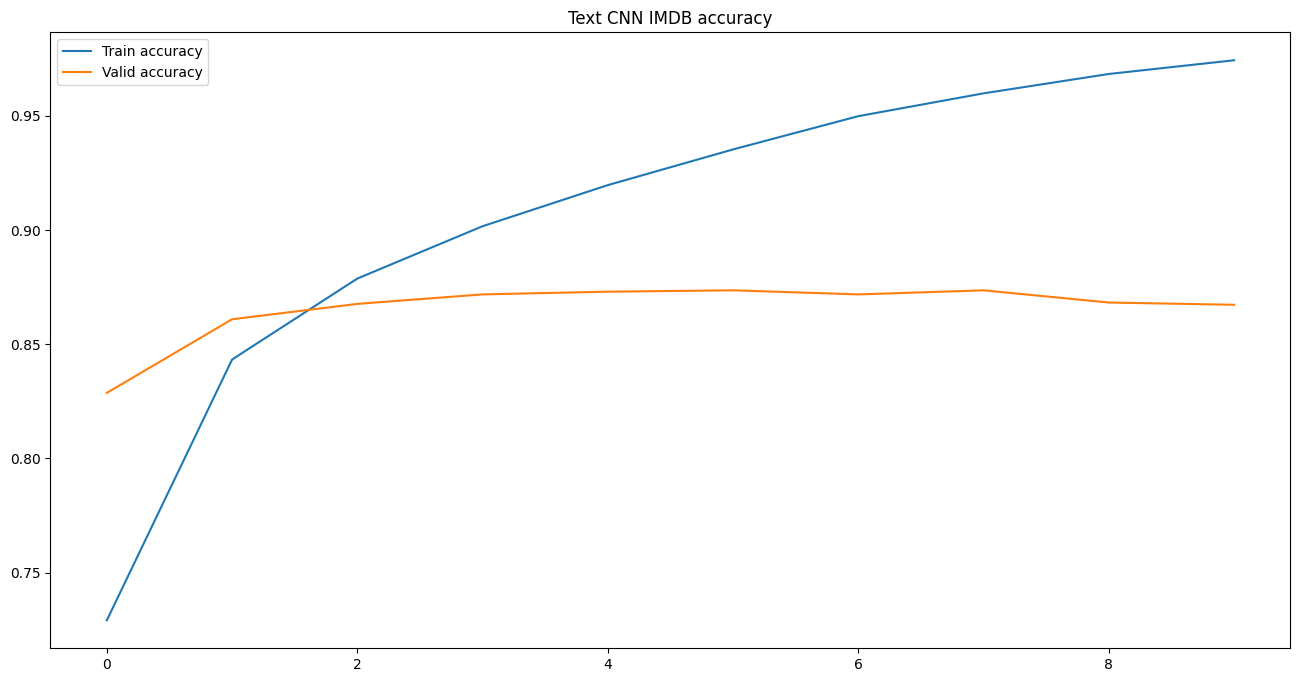

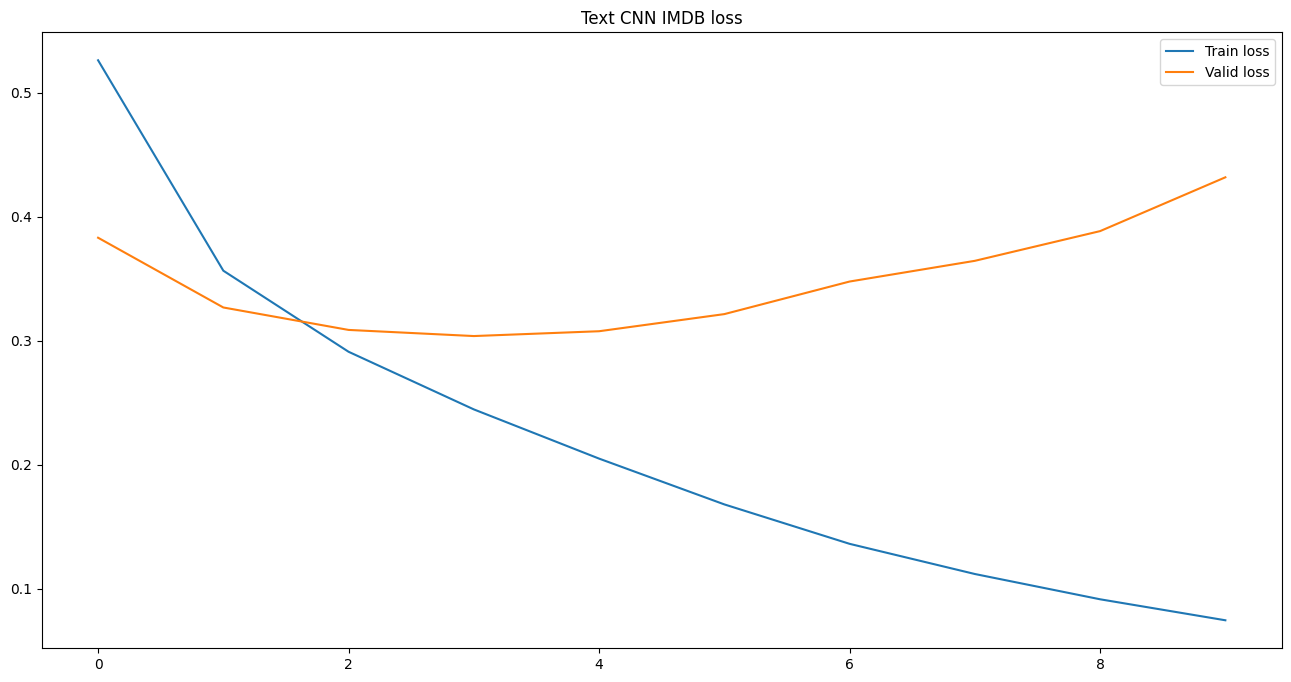

Train Loss: 0.0745, Train Acc: 0.9743
Valid Loss: 0.4316, Vald Acc: 0.8673


In [20]:
# !g1.1
from torch.optim import Adam # Импортируем оптимизатор Adam

# Определение устройства: используем GPU, если доступен, иначе CPU.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print(f"Используемое устройство: {device}")
if torch.cuda.is_available():
    print(f"Название GPU: {torch.cuda.get_device_name()}")

# Функция потерь: Binary Cross Entropy with Logits Loss.
# nn.BCEWithLogitsLoss - это комбинированная функция, которая включает в себя сигмоиду
# и бинарную кросс-энтропию. Она принимает на вход "логиты" (сырые выходы модели)
# и целевые метки (0 или 1).
# Преимущества:
# - Численная стабильность: более стабильна, чем применение сигмоиды и BCE по отдельности.
# - Упрощение: не нужно вручную применять torch.sigmoid в модели или перед функцией потерь.
loss_fn = nn.BCEWithLogitsLoss()

# Перемещаем модель на выбранное устройство (GPU/CPU).
model = model.to(device)

# Оптимизатор Adam:
# Один из самых популярных и эффективных оптимизаторов для глубокого обучения.
# - model.parameters(): Передаем оптимизатору все обучаемые параметры модели.
# - lr (learning rate): Скорость обучения. Гиперпараметр, который контролирует
#   насколько сильно веса модели будут обновляться на каждом шаге.
#   1e-3 (0.001) - это часто хорошее начальное значение по умолчанию.
#   На лекции обсуждались гиперпараметры, и lr - один из ключевых. Его правильный выбор
#   критически важен для сходимости и качества модели.
optimizer = Adam(model.parameters(), lr=1e-3)

# Запускаем цикл обучения на 10 эпох.
# num_epochs - это также гиперпараметр. Слишком мало эпох - недообучение, слишком много - переобучение.
# Из графиков будет видно, что модель начинает переобучаться.
# Это нормальное явление для большинства моделей, и с ним борются с помощью регуляризации
# (например, увеличением dropout, добавлением Batch Normalization, ранней остановкой).
print("\nНачинаем цикл обучения...")
whole_train_valid_cycle(model, 10, 'Text CNN IMDB')

Обсуждение результатов обучения:
- На графиках вы, вероятно, увидите, что `Train Loss` продолжает падать, а `Train Accuracy`
  стремится к 1.0.
- В то же время `Valid Loss` сначала падает, а затем начинает расти, а `Valid Accuracy`
  выходит на плато или даже немного снижается.
- Это классический признак переобучения: модель слишком хорошо запоминает обучающие данные,
  но теряет способность к обобщению на новые (тестовые) данные.
Рекомендации для улучшения (как обсуждалось в лекции/семинаре и общих практиках DL):
1. Увеличить Dropout: Попробовать значения 0.3, 0.4, 0.5.
2. Ранняя остановка (Early Stopping): Прекратить обучение, когда валидационная ошибка перестает улучшаться.
3. Добавить Batch Normalization: Может помочь стабилизировать обучение и улучшить обобщающую способность.
4. Аугментация данных: В случае текстов это может быть синонимическая замена, перестановка слов и т.д.
5. Изменение архитектуры: Использование более сложных RNN (LSTM/GRU) или Transformer-моделей.
6. Подбор lr: Попробовать другие значения скорости обучения (например, 5e-4, 1e-4).
7. Изменить min_freq в Vocabulary: Поэкспериментировать с размером словаря.
8. Использовать большие и более качественные предобученные эмбеддинги (например, FastText 300d).
Этот пример демонстрирует, как получить базовую работающую модель и основные проблемы,
с которыми сталкиваются при ее обучении.